# Relationship between growth limitation and potential predictability

In [23]:
import esm4ppe
import itertools
import xarray as xr
import glob
import matplotlib.pyplot as plt
import matplotlib as mpl
from dask.diagnostics import ProgressBar
import numpy as np
from xhistogram.xarray import histogram

In [24]:
phytotypes = {'diat':{'longname':'Diatoms'},
              'diaz':{'longname':'Diazotrophs'},
              'misc':{'longname':'Miscellaneous'},
              'pico':{'longname':'Picophytoplankton'}}
limitations = {'limfe':{'longname':'Iron',
                        'color':'tab:blue'},
               'limirr':{'longname':'Light',
                         'color':'tab:green'},
               'limn':{'longname':'Nitrate',
                       'color':'tab:orange'},
               'limp':{'longname':'Phosphate',
                       'color':'tab:red'}}

In [25]:
# load correlations
path = esm4ppe.sysconfig['correlationpathroot']+"/pearson.intpp*-lim*.bymonth.nc"
cr = xr.open_mfdataset(path)
# load static
static = esm4ppe.esm4ppeObj('intpp','monthly').static

Opening static... static opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [26]:
initmonth = 1

In [19]:
hs = xr.Dataset()
for phytotype,limitation in itertools.product(phytotypes.keys(),limitations.keys()):
    # Load ppp
    es = esm4ppe.esm4ppeObj('intpp'+phytotype,'monthly').verify('ppp',groupby='month')
    vs = es.vs.sel(month=initmonth)
    try:
        limvalue = limnames[phytotype].index(limitation)
    except:
        continue
    
    name = limitation+phytotype
    # propagate array of correlations out to full length of lead time
    # now histogram each lead time with the appropriate month
    crnow = cr['pearson_intpp'+phytotype+'-'+name]
    nlead = len(vs['lead'])
    montharray = np.tile(cr['month'].to_numpy(),int(nlead/12))
    crnow = crnow.sel(month=montharray).rename({'month':'lead'}).assign_coords({'lead':vs['lead']})
    
    # histogram
    bins = np.linspace(0,1,100)
    tmp = histogram(vs['intpp'+phytotype],
                    crnow,
                    bins=[bins,bins],
                    dim=['xh','yh'],
                    weights=es.static['areacello'],
                    density=True)
    hs[name] = tmp.rename({'intpp'+phytotype+'_bin':'skill','pearson_intpp'+phytotype+'-'+name+'_bin':'correlation'})

Opening static... static opened.
Opening skill metric... skill metric opened.
Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


... (18 outputs left out)

Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


Opening static... static opened.
Opening skill metric... skill metric opened.


/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [20]:
hsnow = {}
for lim
with ProgressBar():
    hsnow = hs['limirrdiat'].compute()

[########################################] | 100% Completed | 2.32 sms


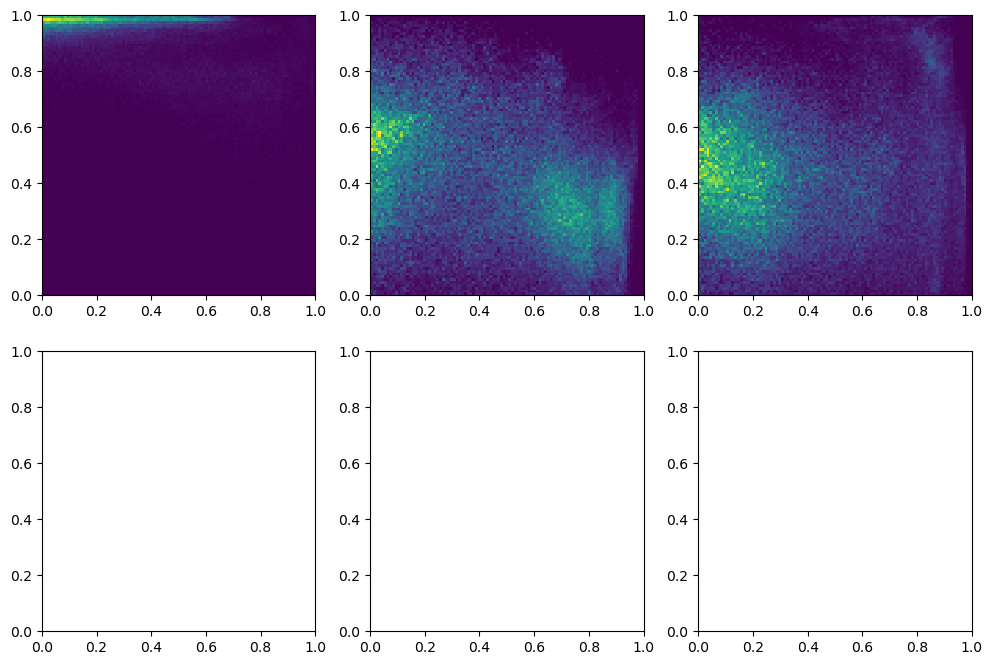

In [22]:
fig,ax = plt.subplots(figsize=(3*4,2*4),nrows=2,ncols=3)
ax[0,0].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=1))
ax[0,1].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=5))
ax[0,2].pcolormesh(hsnow['correlation'],hsnow['skill'],hsnow.sel(lead=9))